# Preparation

In [2]:
import pandas as pd

df = pd.read_csv('gdp_and_crime.csv')

In [3]:
df.dtypes

year                   int64
district              object
crimes                 int64
gdp_purchasers         int64
gdp_agriculture      float64
gdp_manufacturing    float64
gdp_services         float64
dtype: object

In [4]:
len(df.district.unique()) 

118

In [5]:
df.district.value_counts()

district
Alor Gajah    10
Pasir Mas     10
Rompin        10
Rembau        10
Raub          10
              ..
Klang         10
Kerian        10
Keningau      10
Kemaman       10
Yan           10
Name: count, Length: 118, dtype: int64

In [6]:
df.describe()

,year,crimes,gdp_purchasers,gdp_agriculture,gdp_manufacturing,gdp_services
count,1180.000000,1180.000000,1180.000000,1180.000000,1180.000000,1180.000000
mean,2019.500000,409.148305,7878.224576,688.677876,2280.084780,4429.858879
std,2.873499,659.463532,18458.771185,626.941554,6121.720644,11674.859993
min,2015.000000,1.000000,104.000000,16.829047,0.000000,47.402400
25%,2017.000000,75.750000,916.750000,268.789220,29.006638,466.630275
50%,2019.500000,186.000000,2097.500000,453.373263,156.059950,1151.757250
75%,2022.000000,426.750000,7976.250000,970.669400,1152.242650,3969.289417
max,2024.000000,6254.000000,206950.000000,3741.149664,52940.762561,136887.224172


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1180 entries, 0 to 1179
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   year               1180 non-null   int64  
 1   district           1180 non-null   object 
 2   crimes             1180 non-null   int64  
 3   gdp_purchasers     1180 non-null   int64  
 4   gdp_agriculture    1180 non-null   float64
 5   gdp_manufacturing  1180 non-null   float64
 6   gdp_services       1180 non-null   float64
dtypes: float64(3), int64(3), object(1)
memory usage: 64.7+ KB


In [8]:
district_profiles = df.groupby('district').agg({
    'crimes': 'mean',
    'gdp_purchasers': 'mean',
    'gdp_agriculture': 'mean', 
    'gdp_manufacturing': 'mean',
    'gdp_services': 'mean'
}).reset_index()

# Scaling

In [9]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
features_scaled = scaler.fit_transform(district_profiles.drop('district', axis=1))
features_scaled = pd.DataFrame(features_scaled, 
                             columns=district_profiles.columns[1:],
                             index=district_profiles.index)

# First Cut Clustering Modelling
Results: The model is a KMeans algorithm with 4 clusters using all features that have been standard scaler transformed.

Performance: A good silhoutte score of 0.540 but not good enough.

Features: crimes, gdp_purchasers, gdp_manufacturing, gdp_agriculture, and gdp_manufacturing. 

Model selected: KMeans

## Elbow Method

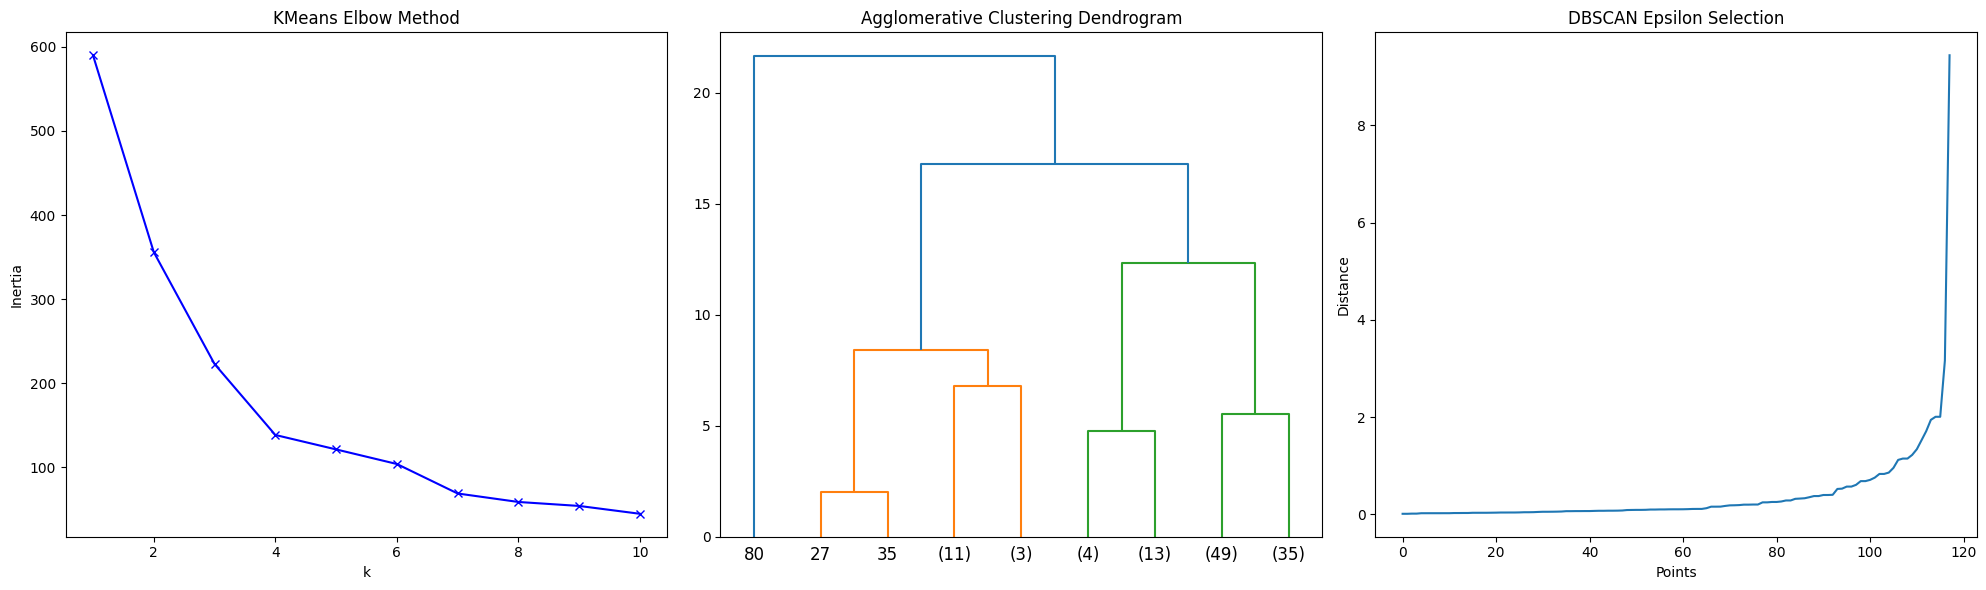

In [10]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
import matplotlib.pyplot as plt
import numpy as np

# KMeans Elbow Method
inertias = []
K = range(1, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(features_scaled)
    inertias.append(kmeans.inertia_)

# Agglomerative Clustering Dendrogram
from scipy.cluster.hierarchy import dendrogram, linkage
linkage_matrix = linkage(features_scaled, method='ward')

# DBSCAN Epsilon Selection
from sklearn.neighbors import NearestNeighbors
neighbors = NearestNeighbors(n_neighbors=2)
neighbors_fit = neighbors.fit(features_scaled)
distances, indices = neighbors_fit.kneighbors(features_scaled)
distances = np.sort(distances, axis=0)
distances = distances[:,1]

# Create subplots for all three methods
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

# Plot KMeans elbow curve
ax1.plot(K, inertias, 'bx-')
ax1.set_xlabel('k')
ax1.set_ylabel('Inertia')
ax1.set_title('KMeans Elbow Method')

# Plot Agglomerative dendrogram
dendrogram(linkage_matrix, ax=ax2, truncate_mode='level', p=3)
ax2.set_title('Agglomerative Clustering Dendrogram')

# Plot DBSCAN epsilon selection
ax3.plot(range(len(distances)), distances)
ax3.set_xlabel('Points')
ax3.set_ylabel('Distance')
ax3.set_title('DBSCAN Epsilon Selection')

plt.tight_layout()
plt.show()

## Optimal Clusters

In [11]:
## Clustering Models

# KMeans Clustering
optimal_k = 4  # Choose based on elbow plot
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
kmeans_clusters = kmeans.fit_predict(features_scaled)
district_profiles['KMeans_Cluster'] = kmeans_clusters

# Agglomerative Clustering
from sklearn.cluster import AgglomerativeClustering
agg_clustering = AgglomerativeClustering(n_clusters=4)  # Choose 3 based on dendrogram
agg_clusters = agg_clustering.fit_predict(features_scaled)
district_profiles['Agglomerative_Cluster'] = agg_clusters

# DBSCAN Clustering
from sklearn.cluster import DBSCAN
eps = 2  # Choose based on epsilon plot
min_samples = 5
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
dbscan_clusters = dbscan.fit_predict(features_scaled)
district_profiles['DBSCAN_Cluster'] = dbscan_clusters


## Evaluate Cluster Performance

In [12]:
# Evaluate silhouette scores for each clustering model
from sklearn.metrics import silhouette_score

# Calculate silhouette scores for each clustering method
silhouette_scores = {
    'KMeans': silhouette_score(features_scaled, district_profiles['KMeans_Cluster']),
    'Agglomerative': silhouette_score(features_scaled, district_profiles['Agglomerative_Cluster']),
    'DBSCAN': silhouette_score(features_scaled, district_profiles['DBSCAN_Cluster'])
}

# Create and sort dataframe of scores
silhouette_df = pd.DataFrame.from_dict(silhouette_scores, orient='index', columns=['Silhouette Score'])
silhouette_df = silhouette_df.sort_values('Silhouette Score', ascending=False)

print("Silhouette Scores by Clustering Method:")
print(silhouette_df.head())

Silhouette Scores by Clustering Method:
               Silhouette Score
DBSCAN                 0.779413
Agglomerative          0.546694
KMeans                 0.539633


## Analyse Clusters

In [13]:
print("\nKMeans Cluster Sizes:")
print(district_profiles['KMeans_Cluster'].value_counts())

# For KMeans, we can calculate the cluster centers directly
cluster_centers = pd.DataFrame(kmeans.cluster_centers_, columns=features_scaled.columns)

# Transform back to original scale
cluster_centers_original = pd.DataFrame(
    scaler.inverse_transform(cluster_centers),
    columns=features_scaled.columns,
    index=cluster_centers.index
)

print("\nCluster Center Values:")
print(cluster_centers_original)


KMeans Cluster Sizes:
KMeans_Cluster
0    87
2    17
3    13
1     1
Name: count, dtype: int64

Cluster Center Values:
        crimes  gdp_purchasers  gdp_agriculture  gdp_manufacturing  \
0   217.502299     2767.824138       453.713210         594.153890   
1  2884.800000   170933.700000        41.676779       44160.150200   
2   369.805882     6724.982353      1851.156736        1270.008643   
3  1552.715385    31043.953846       790.738372       11662.178346   

    gdp_services  
0    1568.366803  
1  111395.566534  
2    3207.012693  
3   16950.819502  


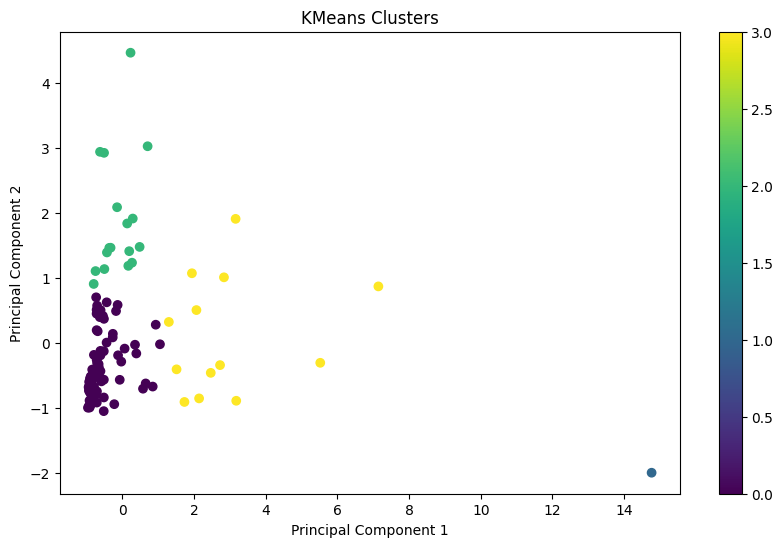

In [14]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce dimensionality to 2D for visualization
pca = PCA(n_components=2)
features_2d = pca.fit_transform(features_scaled)

# Plotting
plt.figure(figsize=(10, 6))
plt.scatter(features_2d[:, 0], features_2d[:, 1], c=district_profiles['KMeans_Cluster'])
plt.title('KMeans Clusters')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar()
plt.show()

## Nested Clustering Model

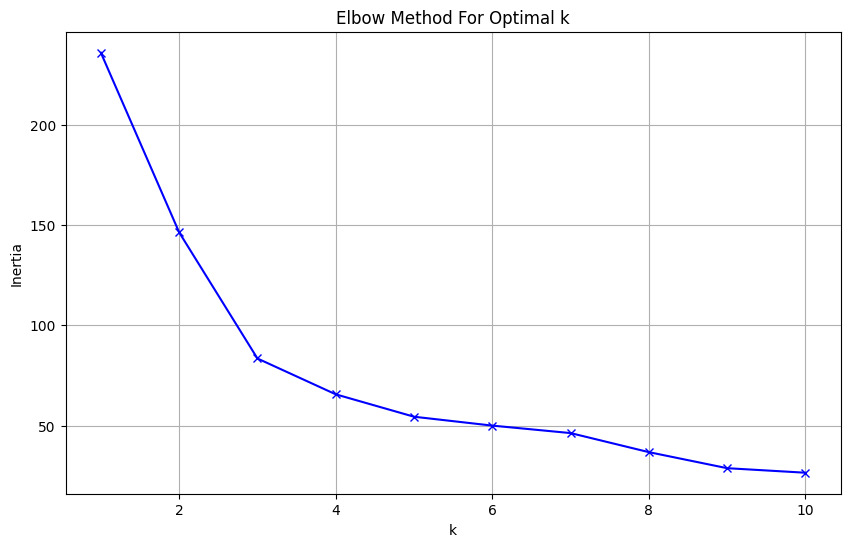

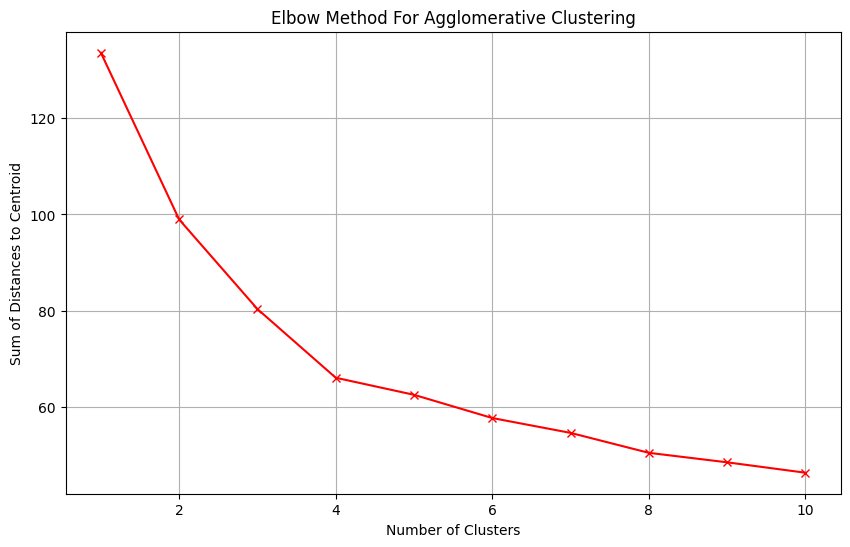

In [15]:
# Get data from main cluster only
main_cluster_mask = district_profiles['DBSCAN_Cluster'] == 0
main_cluster_data = features_scaled[main_cluster_mask]

# Calculate inertia for different k values (Elbow method)
inertias = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(main_cluster_data)
    inertias.append(kmeans.inertia_)

# Plot elbow curve for K-means
plt.figure(figsize=(10, 6))
plt.plot(k_values, inertias, 'bx-')
plt.xlabel('k')
plt.ylabel('Inertia')
plt.title('Elbow Method For Optimal k')
plt.grid(True)
plt.show()

# Calculate distances for different numbers of clusters (Agglomerative)
distances = []
for k in k_values:
    agg = AgglomerativeClustering(n_clusters=k)
    labels = agg.fit_predict(main_cluster_data)
    
    # Calculate average distance to cluster center using numpy arrays
    distance = 0
    for i in range(k):
        cluster_points = main_cluster_data[labels == i].values  # Convert to numpy array
        centroid = np.mean(cluster_points, axis=0)
        distance += sum(np.linalg.norm(point - centroid) for point in cluster_points)
    distances.append(distance)

# Plot elbow curve for Agglomerative
plt.figure(figsize=(10, 6))
plt.plot(k_values, distances, 'rx-')
plt.xlabel('Number of Clusters')
plt.ylabel('Sum of Distances to Centroid')
plt.title('Elbow Method For Agglomerative Clustering')
plt.grid(True)
plt.show()

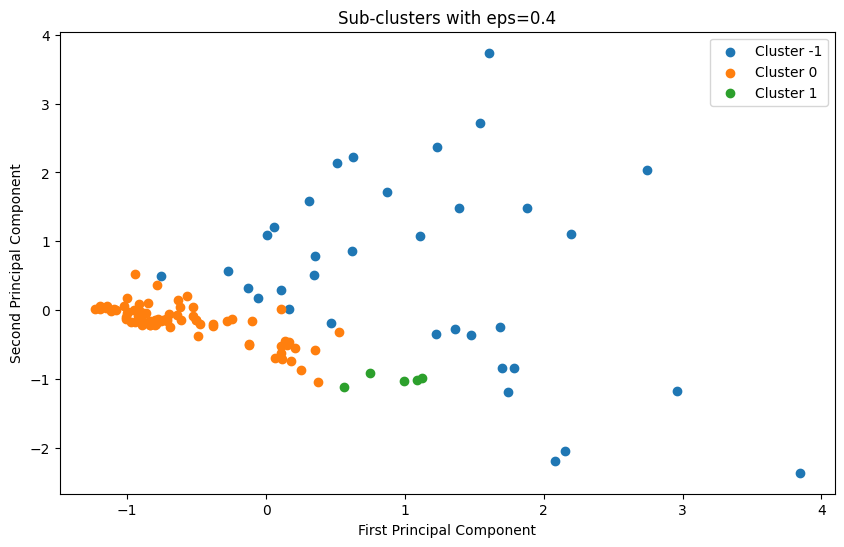


Results for eps=0.4:
Number of clusters: 2
Number of noise points: 35
Silhouette score: 0.569
Cluster sizes:
-1    35
 0    74
 1     5
Name: count, dtype: int64


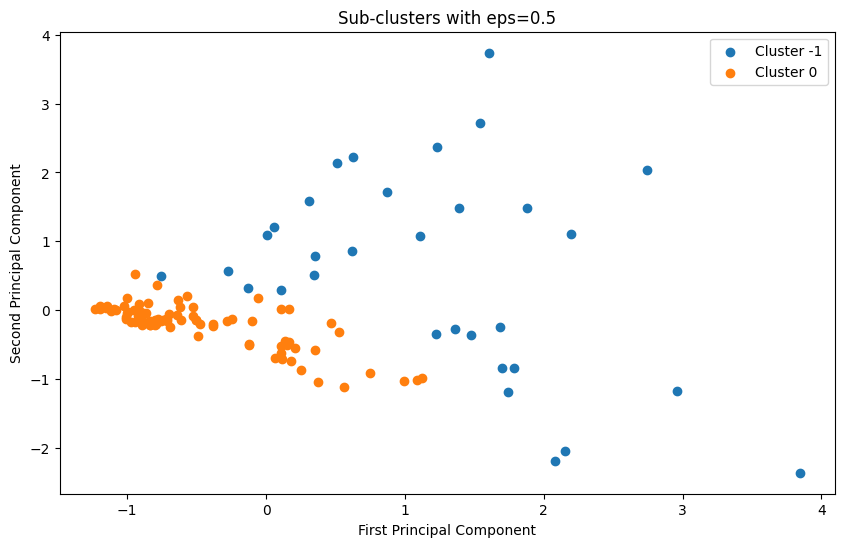


Results for eps=0.5:
Number of clusters: 1
Number of noise points: 32
Silhouette score: N/A
Cluster sizes:
-1    32
 0    82
Name: count, dtype: int64


In [16]:
# Try both epsilon values
eps_values = [0.4, 0.5]

for eps in eps_values:
    # Perform DBSCAN with current epsilon
    dbscan = DBSCAN(eps=eps, min_samples=5)
    sub_clusters = dbscan.fit_predict(main_cluster_data)
    
    # Calculate silhouette score (ignoring noise points labeled as -1)
    mask = sub_clusters != -1
    if len(np.unique(sub_clusters[mask])) > 1:  # Need at least 2 clusters for silhouette score
        score = silhouette_score(main_cluster_data[mask], sub_clusters[mask])
    else:
        score = None
    
    # Visualize results
    plt.figure(figsize=(10, 6))
    pca = PCA(n_components=2)
    features_pca = pca.fit_transform(main_cluster_data)
    
    # Plot clusters
    unique_clusters = np.unique(sub_clusters)
    for cluster in unique_clusters:
        mask = sub_clusters == cluster
        plt.scatter(features_pca[mask, 0], features_pca[mask, 1], 
                   label=f'Cluster {cluster}')
    
    plt.title(f'Sub-clusters with eps={eps}')
    plt.xlabel('First Principal Component')
    plt.ylabel('Second Principal Component')
    plt.legend()
    plt.show()
    
    # Print cluster information
    print(f"\nResults for eps={eps}:")
    print(f"Number of clusters: {len(np.unique(sub_clusters[sub_clusters != -1]))}")
    print(f"Number of noise points: {np.sum(sub_clusters == -1)}")
    print(f"Silhouette score: {score:.3f}" if score else "Silhouette score: N/A")
    print("Cluster sizes:")
    print(pd.Series(sub_clusters).value_counts().sort_index())

# Second Cut Clustering Model

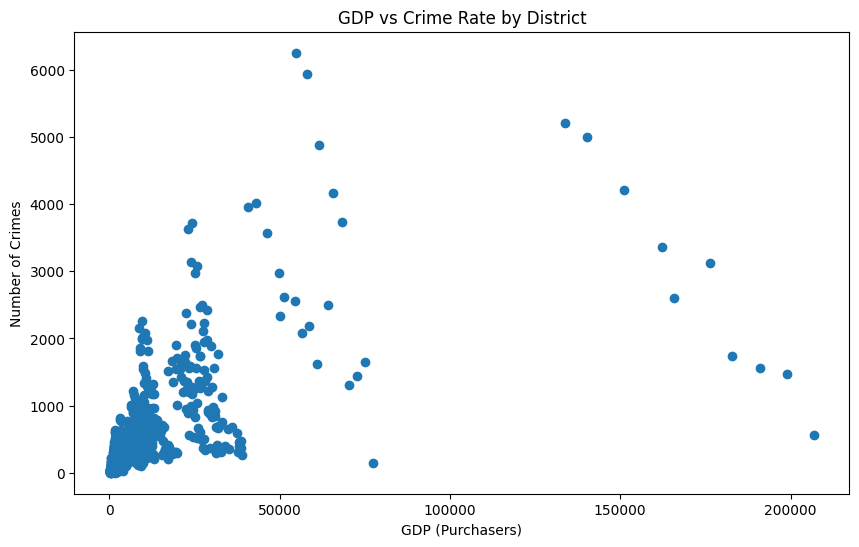

In [17]:
# Create scatter plot of GDP vs Crimes
plt.figure(figsize=(10, 6))
plt.scatter(df['gdp_purchasers'], df['crimes'])
plt.xlabel('GDP (Purchasers)')
plt.ylabel('Number of Crimes')
plt.title('GDP vs Crime Rate by District')
plt.show()


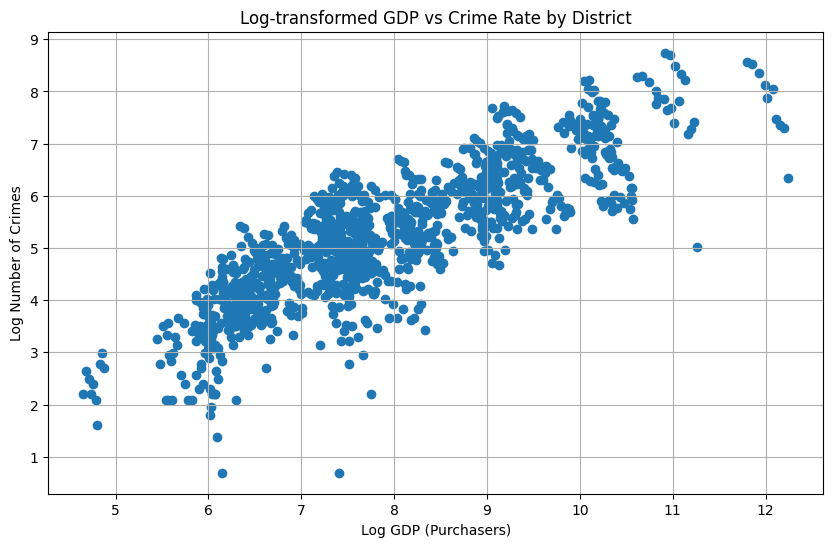

In [18]:
import numpy as np

# Create log-transformed features
features_log = df[['crimes', 'gdp_purchasers']].copy()
features_log['gdp_purchasers'] = np.log1p(features_log['gdp_purchasers'])  # log1p handles zero values
features_log['crimes'] = np.log1p(features_log['crimes'])  # log1p handles zero values

# Visualize transformed data
plt.figure(figsize=(10, 6))
plt.scatter(features_log['gdp_purchasers'], features_log['crimes'])
plt.xlabel('Log GDP (Purchasers)')
plt.ylabel('Log Number of Crimes')
plt.title('Log-transformed GDP vs Crime Rate by District')
plt.grid(True)
plt.show()

# Scale the transformed features for clustering
features_scaled = StandardScaler().fit_transform(features_log)
features_scaled = pd.DataFrame(features_scaled, columns=features_log.columns)

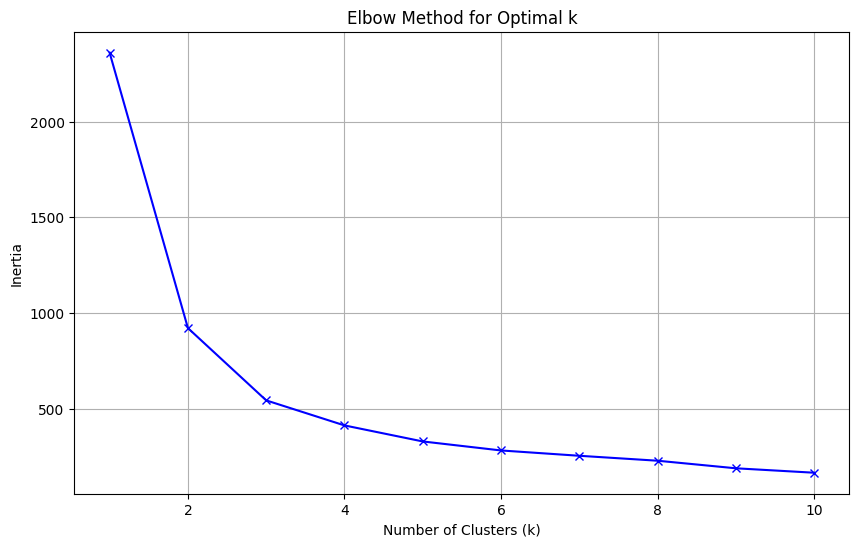


Results for k=4:
Number of clusters: 4
Silhouette score: 0.421

Cluster sizes:
0    469
1    275
2    302
3    134
Name: count, dtype: int64


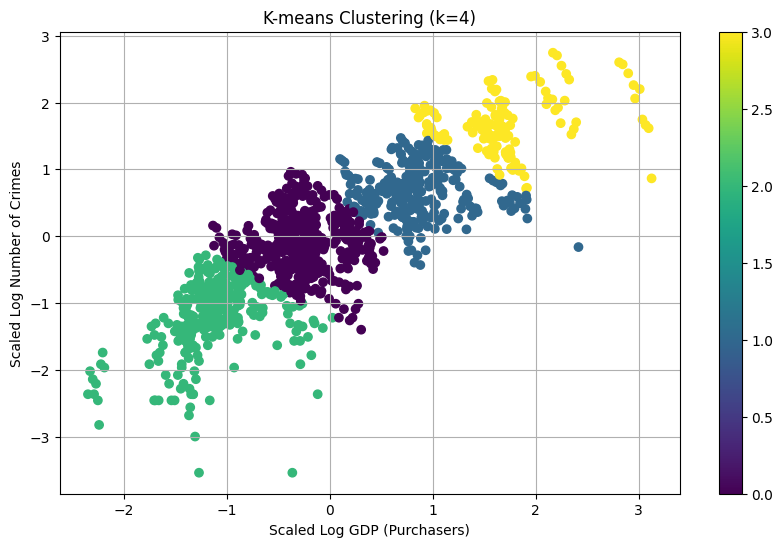

In [19]:
# Calculate inertia for different numbers of clusters
inertias = []
K = range(1, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(features_scaled)
    inertias.append(kmeans.inertia_)

# Plot elbow curve
plt.figure(figsize=(10, 6))
plt.plot(K, inertias, 'bx-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.grid(True)
plt.show()

# Based on elbow curve, choose optimal number of clusters
optimal_k = 4  # Adjust this based on elbow curve
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
clusters = kmeans.fit_predict(features_scaled)

# Calculate silhouette score
score = silhouette_score(features_scaled, clusters)

# Print clustering results
print(f"\nResults for k={optimal_k}:")
print(f"Number of clusters: {optimal_k}")
print(f"Silhouette score: {score:.3f}")
print("\nCluster sizes:")
print(pd.Series(clusters).value_counts().sort_index())

# Visualize the clusters
plt.figure(figsize=(10, 6))
scatter = plt.scatter(features_scaled['gdp_purchasers'],
                     features_scaled['crimes'],
                     c=clusters,
                     cmap='viridis')
plt.colorbar(scatter)
plt.xlabel('Scaled Log GDP (Purchasers)')
plt.ylabel('Scaled Log Number of Crimes')
plt.title(f'K-means Clustering (k={optimal_k})')
plt.grid(True)
plt.show()


# Third Cut Clustering Model

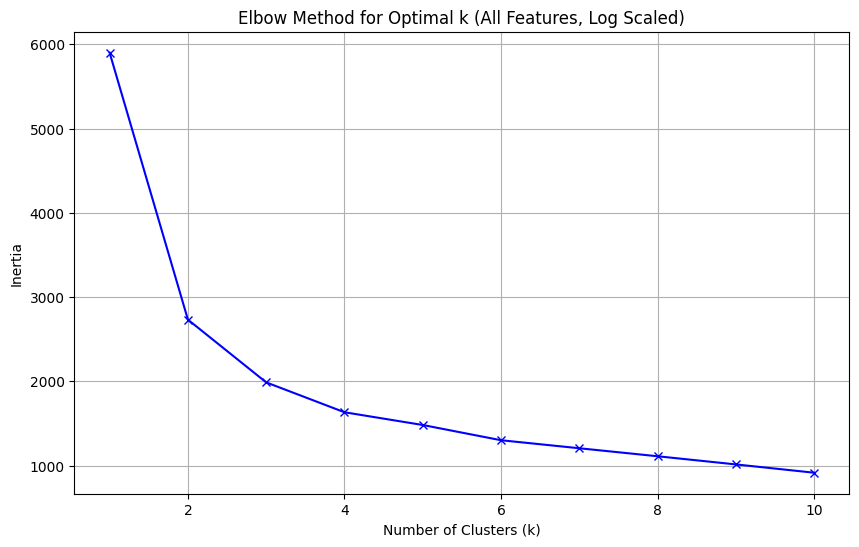


Results for k=4:
Number of clusters: 4
Silhouette score: 0.313

Cluster sizes:
0    404
1    296
2    281
3    199
Name: count, dtype: int64


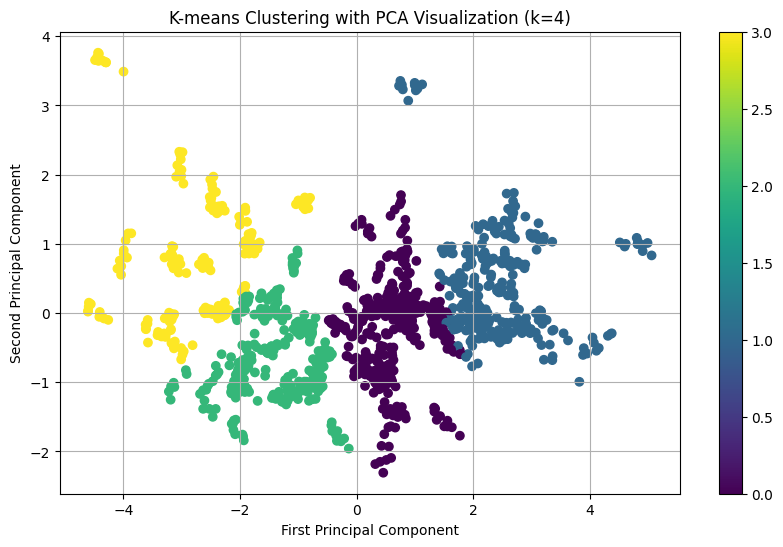


PCA explained variance ratio: [0.75776168 0.16747504]


In [20]:
# Scale all features using log transformation
features_log = pd.DataFrame()
for column in ['crimes', 'gdp_purchasers', 'gdp_agriculture', 'gdp_manufacturing', 'gdp_services']:
    features_log[column] = np.log1p(df[column])

# Scale the log-transformed features
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features_log)
features_scaled = pd.DataFrame(features_scaled, columns=features_log.columns)

# Try different values of k
K = range(1, 11)
inertias = []

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(features_scaled)
    inertias.append(kmeans.inertia_)

# Plot elbow curve
plt.figure(figsize=(10, 6))
plt.plot(K, inertias, 'bx-')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k (All Features, Log Scaled)')
plt.grid(True)
plt.show()

# Based on elbow curve, choose optimal number of clusters
optimal_k = 4  # Adjust this based on elbow curve
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
clusters = kmeans.fit_predict(features_scaled)

# Calculate silhouette score
score = silhouette_score(features_scaled, clusters)

# Print clustering results
print(f"\nResults for k={optimal_k}:")
print(f"Number of clusters: {optimal_k}")
print(f"Silhouette score: {score:.3f}")
print("\nCluster sizes:")
print(pd.Series(clusters).value_counts().sort_index())

# Create a PCA model to reduce dimensions for visualization
pca = PCA(n_components=2)
features_pca = pca.fit_transform(features_scaled)

# Visualize the clusters using PCA components
plt.figure(figsize=(10, 6))
scatter = plt.scatter(features_pca[:, 0], 
                     features_pca[:, 1],
                     c=clusters,
                     cmap='viridis')
plt.colorbar(scatter)
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title(f'K-means Clustering with PCA Visualization (k={optimal_k})')
plt.grid(True)
plt.show()

# Print explained variance ratio
print("\nPCA explained variance ratio:", pca.explained_variance_ratio_)


# Model Evaluation

The best and most meaningful model we found was the Agglomerative clustering algorithm in first cut with all features with only MinMax Scaling applied.</br>
This model has 4 clusters as follows:


In [21]:
cluster_centers_original.head()

,crimes,gdp_purchasers,gdp_agriculture,gdp_manufacturing,gdp_services
0,217.502299,2767.824138,453.713210,594.153890,1568.366803
1,2884.800000,170933.700000,41.676779,44160.150200,111395.566534
2,369.805882,6724.982353,1851.156736,1270.008643,3207.012693
3,1552.715385,31043.953846,790.738372,11662.178346,16950.819502


In [22]:
sorted_clusters = cluster_centers_original.sort_values(by='crimes')
print("Cluster with lowest crime rate:")
print(sorted_clusters.iloc[0])
print("\nCluster with second lowest crime rate:")
print(sorted_clusters.iloc[1])
print("\nCluster with second highest crime rate:")
print(sorted_clusters.iloc[2])
print("\nCluster with highest crime rate:")
print(sorted_clusters.iloc[3])


Cluster with lowest crime rate:
crimes                217.502299
gdp_purchasers       2767.824138
gdp_agriculture       453.713210
gdp_manufacturing     594.153890
gdp_services         1568.366803
Name: 0, dtype: float64

Cluster with second lowest crime rate:
crimes                369.805882
gdp_purchasers       6724.982353
gdp_agriculture      1851.156736
gdp_manufacturing    1270.008643
gdp_services         3207.012693
Name: 2, dtype: float64

Cluster with second highest crime rate:
crimes                1552.715385
gdp_purchasers       31043.953846
gdp_agriculture        790.738372
gdp_manufacturing    11662.178346
gdp_services         16950.819502
Name: 3, dtype: float64

Cluster with highest crime rate:
crimes                 2884.800000
gdp_purchasers       170933.700000
gdp_agriculture          41.676779
gdp_manufacturing     44160.150200
gdp_services         111395.566534
Name: 1, dtype: float64


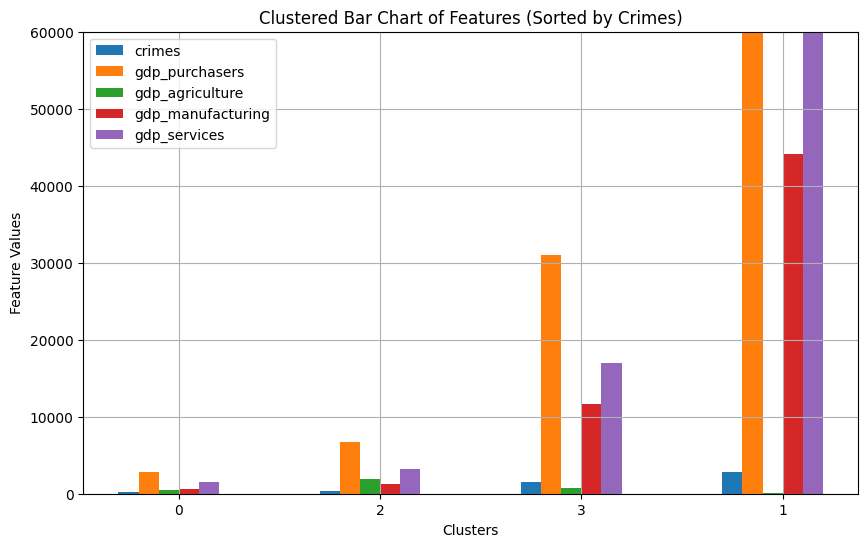

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# Assuming cluster_centers_original is a DataFrame with cluster labels as index and features as columns
# Sorting the DataFrame by 'crimes' in ascending order
cluster_centers_sorted = cluster_centers_original.sort_values(by='crimes')

features = cluster_centers_sorted.columns.tolist()
clusters = cluster_centers_sorted.index.tolist()

# Plotting
plt.figure(figsize=(10, 6))
x = np.arange(len(clusters))  # the label locations
width = 0.1  # the width of the bars

for i, feature in enumerate(features):
    plt.bar(x + i * width, cluster_centers_sorted[feature], width, label=feature)

plt.xlabel('Clusters')
plt.ylabel('Feature Values')
plt.title('Clustered Bar Chart of Features (Sorted by Crimes)')
plt.xticks(x + width * len(features) / 2, clusters)
plt.ylim(0,60_000)
plt.legend()
plt.grid(True)
plt.show()

Cluster Statistics:

Mean values for each cluster:
              crimes  gdp_purchasers  gdp_agriculture  gdp_manufacturing  \
cluster                                                                    
0        1396.025000    31752.020000       622.374250       10357.144665   
1         170.612821     1830.207692       677.198320         135.526815   
2          68.822581      641.877419       231.412432          19.362349   
3         413.271429     7261.207143      1258.285159        2000.761862   

         gdp_services  
cluster                
0        18733.176250  
1          936.255056  
2          355.618992  
3         3590.060244  

Standard deviation for each cluster:
              crimes  gdp_purchasers  gdp_agriculture  gdp_manufacturing  \
cluster                                                                    
0        1092.345728    35673.221085       523.078722       11472.092270   
1         108.744371      653.621000       540.934343         137.150129   
2     

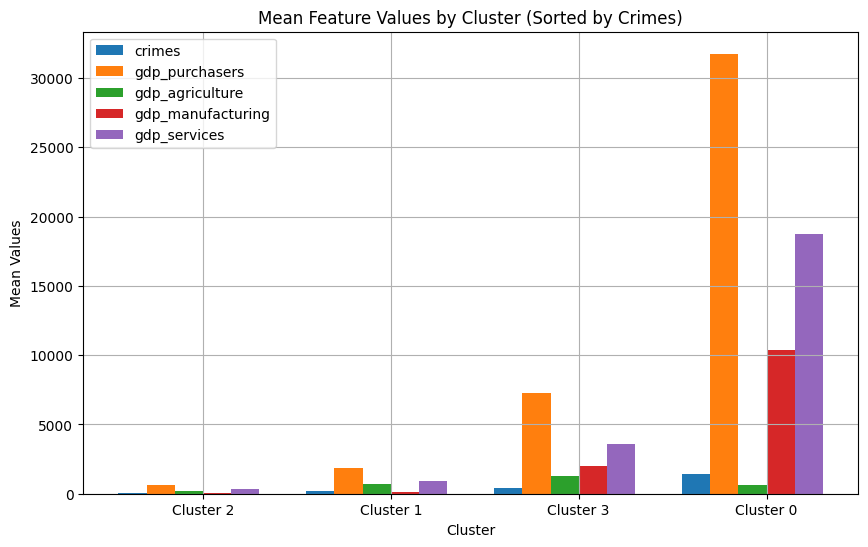

In [33]:
# Perform Agglomerative Clustering
from sklearn.cluster import AgglomerativeClustering

# Create and fit the clustering model 
n_clusters = 4  # Based on previous analysis
agg_clustering = AgglomerativeClustering(n_clusters=n_clusters)
df['cluster'] = agg_clustering.fit_predict(features_scaled)

# Calculate cluster statistics
features = ['crimes', 'gdp_purchasers', 'gdp_agriculture', 'gdp_manufacturing', 'gdp_services']
cluster_stats = df.groupby('cluster')[features].agg(['mean', 'std', 'min', 'max'])

# Print cluster statistics
print("Cluster Statistics:")
print("\nMean values for each cluster:")
cluster_means = df.groupby('cluster')[features].mean()
print(cluster_means)

print("\nStandard deviation for each cluster:")
cluster_stds = df.groupby('cluster')[features].std()
print(cluster_stds)

# Sort clusters by mean crime rate
cluster_means_sorted = cluster_means.sort_values(by='crimes')
sorted_cluster_indices = cluster_means_sorted.index

# Plotting mean values for each feature by cluster
plt.figure(figsize=(10, 6))

x = np.arange(len(sorted_cluster_indices))
width = 0.15

for i, feature in enumerate(features):
    plt.bar(x + i * width, cluster_means_sorted[feature], width, label=feature)

plt.xlabel('Cluster')
plt.ylabel('Mean Values')
plt.title('Mean Feature Values by Cluster (Sorted by Crimes)')
plt.xticks(x + width * len(features)/2, [f'Cluster {i}' for i in sorted_cluster_indices])
plt.legend()
plt.grid(True)
plt.show()



In [35]:
# Calculate mean crimes for each cluster and sort by increasing crime
mean_crimes = df.groupby('cluster')['crimes'].mean().sort_values()
print("\nMean crimes for each cluster (sorted):")
print(mean_crimes)



Mean crimes for each cluster (sorted):
cluster
2      68.822581
1     170.612821
3     413.271429
0    1396.025000
Name: crimes, dtype: float64
